#  Сегментация изображений

## Задачи для совместного разбора

1\. Рассмотрите пример работы слоя `ConvTranspose2d`.

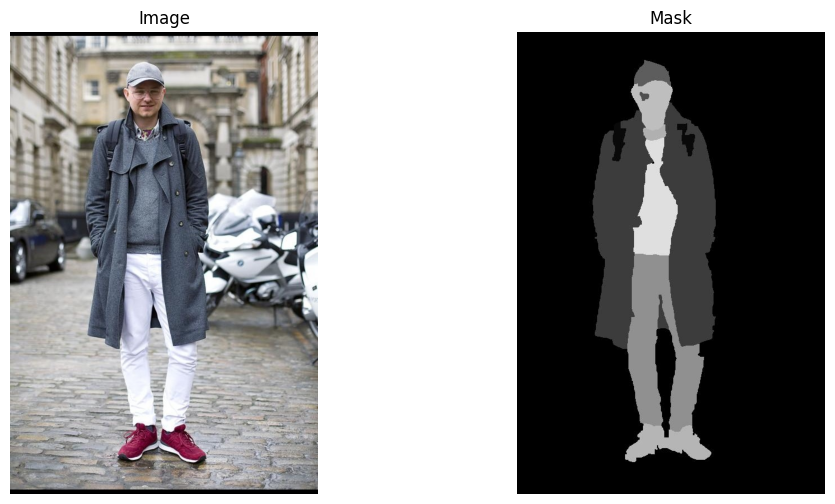

In [3]:
 from PIL import Image
import matplotlib.pyplot as plt

def show_image_and_mask(image_path, mask_path):
    """
    Отображает изображение и маску рядом.

    Args:
        image_path (str): Путь к изображению (JPEG).
        mask_path (str): Путь к маске (JPEG).
    """
    # Загрузка изображения и маски
    image = Image.open(image_path)
    mask = Image.open(mask_path)

    # Настройка фигуры для отображения
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Отображение изображения
    axes[0].imshow(image)
    axes[0].axis('off')
    axes[0].set_title('Image')

    # Отображение маски
    axes[1].imshow(mask, cmap='gray')
    axes[1].axis('off')
    axes[1].set_title('Mask')

    plt.show()

# Пример использования
image_path = "/kaggle/input/people-clothing-segmentation/jpeg_images/IMAGES/img_0004.jpeg"  # Укажите путь к изображению
mask_path = "/kaggle/input/people-clothing-segmentation/jpeg_masks/MASKS/seg_0004.jpeg"    # Укажите путь к маске

show_image_and_mask(image_path, mask_path)

In [4]:
import numpy as np
np.unique(plt.imread(mask_path))

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55], dtype=uint8)

In [6]:
import pandas as pd

data = '/kaggle/input/people-clothing-segmentation/labels.csv'

labels = pd.read_csv(data)
labels.drop(columns="Unnamed: 0", inplace=True)
labels

,label_list
0,NaN
1,accessories
2,bag
3,belt
4,blazer
5,blouse
6,bodysuit
7,boots
8,bra
9,bracelet


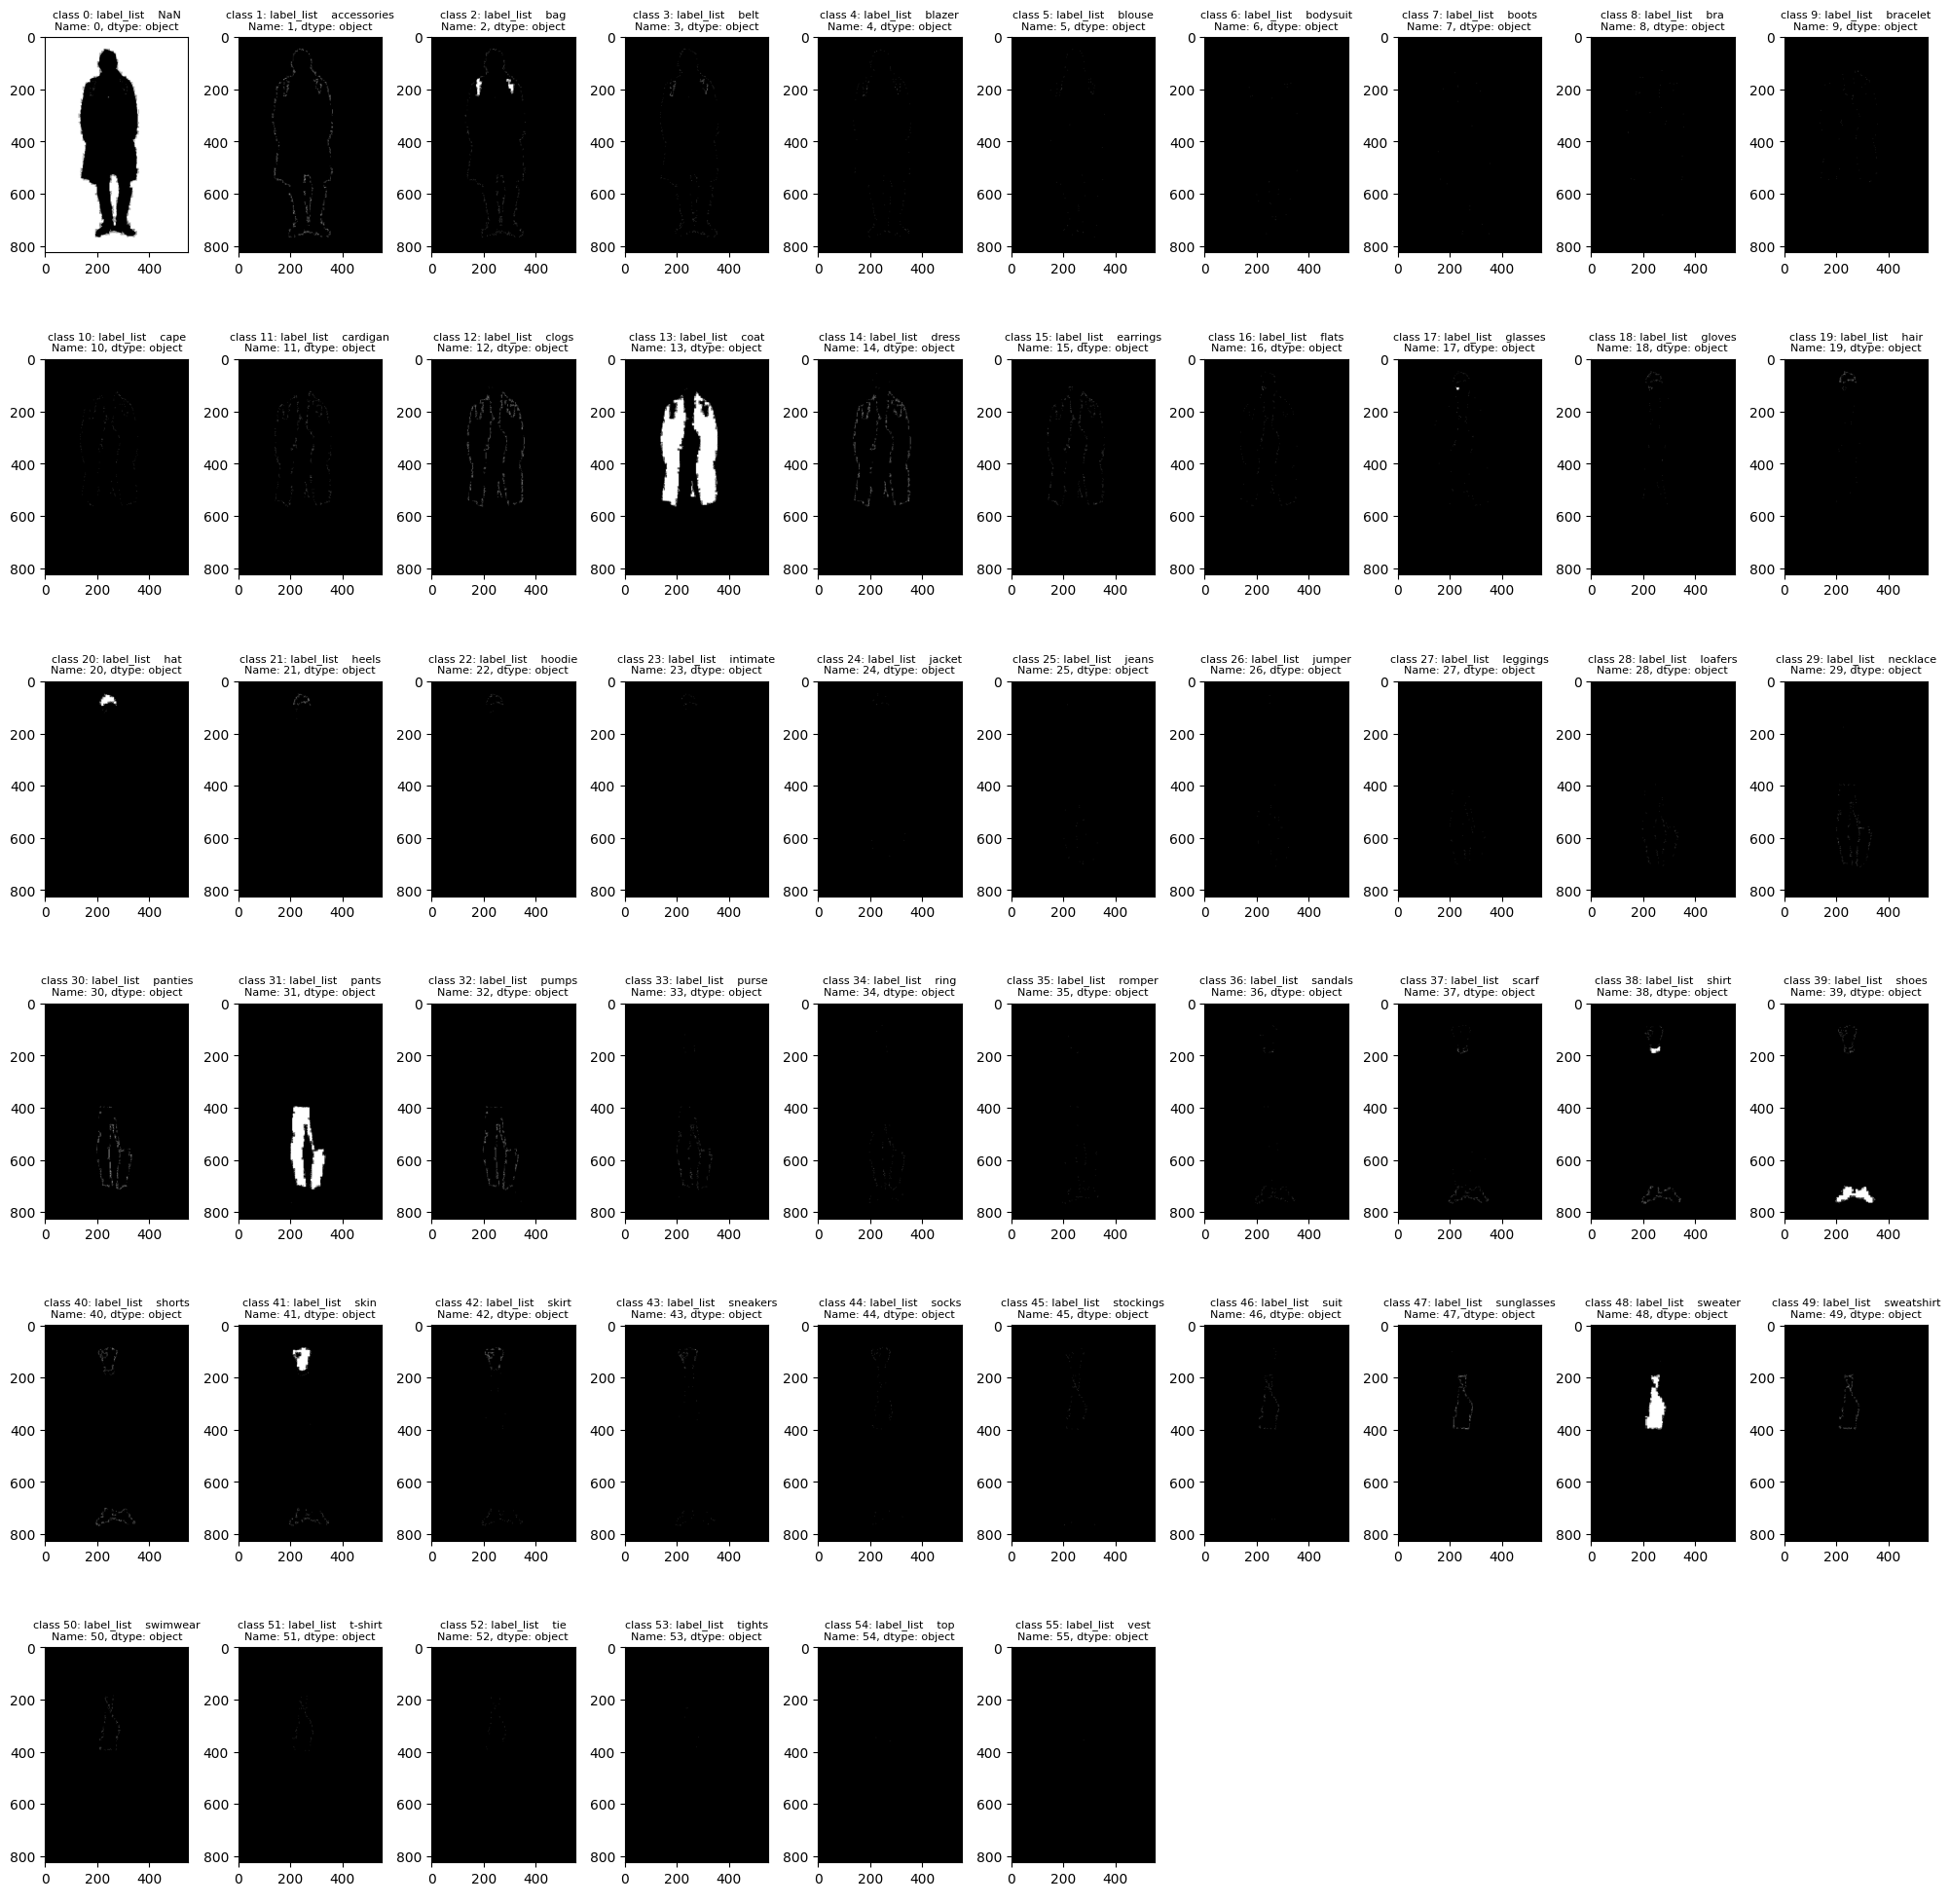

In [7]:
mask = plt.imread(mask_path)

# Определяем количество строк и столбцов в сетке
ncols = 10  # Количество столбцов
nrows = (58 + ncols - 1) // ncols  # Высчитываем количество строк

# Создаём подграфики
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 20))

# Перебираем все классы
for i, ax in enumerate(axes.flatten()):
    if i < 58:
        # Условие: если класс i присутствует в маске
        if i in mask:
            # Создаём изображение с замаскированным только классом i
            class_mask = np.zeros_like(mask)  # Пустая маска
            class_mask[mask == i] = 1  # Оставляем только пиксели для класса i

            # Визуализация
            ax.imshow(class_mask, cmap='gray')  # Отображаем как ч/б изображение
            ax.set_title(f'class {i}: {labels.loc[i]}', fontsize=8)
        else:
            # Если класса нет, оставляем пустую фигуру
            ax.axis('off')
    else:
        # Отключаем оси для лишних ячеек
        ax.axis('off')

plt.tight_layout()
plt.show()

<p class="task" id="1"></p>

2\. Опишите датасет `ClothesSegmentationDataset`. Реализуйте `__getitem__` таким образом, чтобы он возвращал два элемента: тензор с изображением и тензор с маской. Маска должна быть представлена трехмерным тензором целых чисел. Предусмотрите возможность передавать извне при создании датасета набор преобразований для изображений и масок. Создайте объект датасета и выведите на экран форму и типы одного изображения и его маски.

In [8]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from torchvision.transforms.functional import InterpolationMode
from PIL import Image
import os

class ClothesSegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_transform=None, mask_transform=None):
        """
        Параметры:
        - image_dir: путь к директории с изображениями.
        - mask_dir: путь к директории с масками.
        - image_transform: преобразования для изображений.
        - mask_transform: преобразования для масок.
        """
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_transform = image_transform
        self.mask_transform = mask_transform

        # Список всех файлов изображений и масок
        self.images = sorted(os.listdir(image_dir))
        self.masks = sorted(os.listdir(mask_dir))

        assert len(self.images) == len(self.masks), "Количество изображений и масок должно совпадать"

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        # Загрузка изображения и маски
        image_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])
    
        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path)
    
        # Применение преобразований
        if self.image_transform:
            image = self.image_transform(image)
        if self.mask_transform:
            mask = self.mask_transform(mask)
    
        # Преобразование маски в numpy-массив, затем в тензор
        mask = torch.from_numpy(np.array(mask)).long()
    
        return image, mask


# Пути к изображениям и маскам
image_dir = "/kaggle/input/people-clothing-segmentation/png_images/IMAGES"
mask_dir = "/kaggle/input/people-clothing-segmentation/png_masks/MASKS"

# Преобразования для изображений и масок
image_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.2, 0.2, 0.2]),
])
mask_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.NEAREST),
])

# Создаем датасет
dataset = ClothesSegmentationDataset(
    image_dir=image_dir,
    mask_dir=mask_dir,
    image_transform=image_transform,
    mask_transform=mask_transform
)

# Вывод формы и типов одного примера
image, mask = dataset[0]
print(f"Форма изображения: {image.shape}, тип: {image.dtype}")
print(f"Форма маски: {mask.shape}, тип: {mask.dtype}")

Форма изображения: torch.Size([3, 256, 256]), тип: torch.float32
Форма маски: torch.Size([256, 256]), тип: torch.int64


<p class="task" id="2"></p>

3\. Напишите функцию `show_image_with_mask`, которая выводит рядом два изображения: фотографию и маску. Продемонстрируйте работу функции, взяв один пример из созданного датасета.


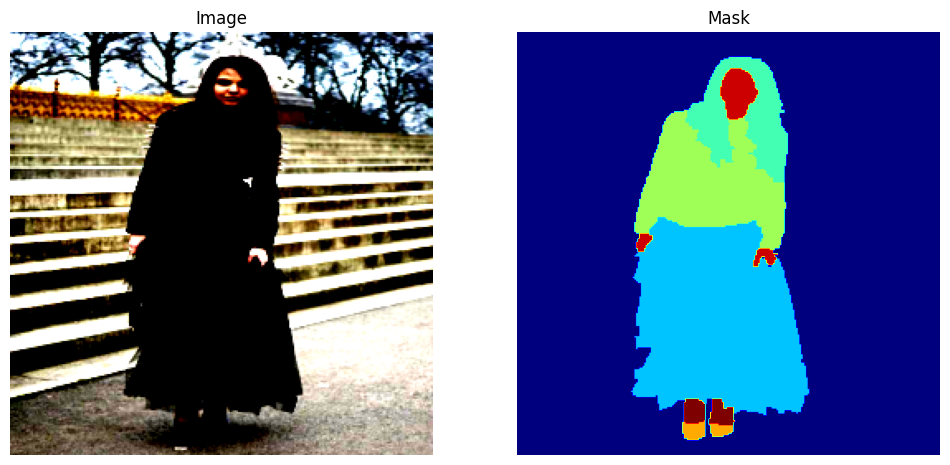

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def show_image_with_mask(image, mask):
    """
    Функция для отображения изображения и маски рядом.
    :param image: Тензор изображения (C, H, W).
    :param mask: Маска, объект типа PIL.Image.
    """
    # Преобразуем изображение в numpy для отображения
    image = image.permute(1, 2, 0).cpu().numpy()  # Переводим (C, H, W) -> (H, W, C)
    
    # Преобразуем маску в тензор, если это PIL.Image
    if isinstance(mask, torch.Tensor):
        mask = mask.cpu().numpy()
    else:
        mask = np.array(mask)

    # Настроим график
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Показываем изображение
    axes[0].imshow(image)
    axes[0].set_title('Image')
    axes[0].axis('off')  # Убираем оси

    # Показываем маску
    axes[1].imshow(mask, cmap='jet')  # Используем цветовую карту для маски
    axes[1].set_title('Mask')
    axes[1].axis('off')  # Убираем оси

    plt.show()


# Пример использования с одним элементом из датасета
image, mask = dataset[1]  # Берем первый элемент

show_image_with_mask(image, mask)

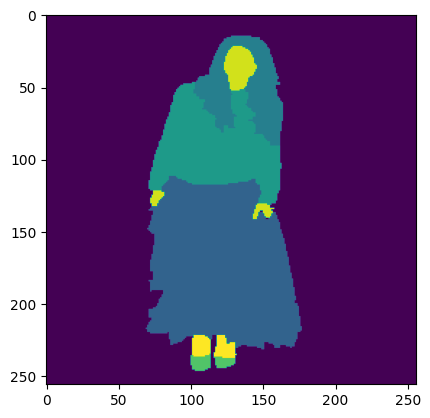

In [7]:
plt.imshow(mask)

In [8]:
np.unique(mask)

array([ 0, 14, 19, 24, 32, 41, 44])

<p class="task" id="3"></p>

4\. Реализуйте архитектуру U-Net. Реализуйте модель таким образом, чтобы на выходе для каждого изображения получался тензор размера `n_classes x h x w`, где `n_classes` - количество уникальных значений в масках, а `h` и `w` - размер исходного изображения. Возьмите один пример из набора данных и пропустите его через сеть. Выведите форму полученного результата на экран. 

In [9]:
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self, in_channels, n_classes):
        super(UNet, self).__init__()

        # Encoder
        self.enc1 = self.conv_block(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2, 2, return_indices=True)
        self.enc2 = self.conv_block(64, 128)
        self.pool2 = nn.MaxPool2d(2, 2, return_indices=True)

        # Bridge
        self.bridge = self.conv_block(128, 128)

        # Decoder
        self.unpool2 = nn.MaxUnpool2d(2, 2)
        self.dec2 = self.conv_block(128, 64)
        self.unpool1 = nn.MaxUnpool2d(2, 2)
        self.dec1 = self.conv_block(64, 64)

        # Final Convolution
        self.final_conv = nn.Conv2d(64, n_classes, kernel_size=1)

    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        # Encoder
        x1 = self.enc1(x)
        x1_pooled, indices1 = self.pool1(x1)
        x2 = self.enc2(x1_pooled)
        x2_pooled, indices2 = self.pool2(x2)

        # Bridge
        x_bridge = self.bridge(x2_pooled)

        # Decoder
        x2_unpooled = self.unpool2(x_bridge, indices2, output_size=x2.size())
        x2_decoded = self.dec2(x2_unpooled)
        x1_unpooled = self.unpool1(x2_decoded, indices1, output_size=x1.size())
        x1_decoded = self.dec1(x1_unpooled)

        # Final Convolution
        output = self.final_conv(x1_decoded)

        return output

# Параметры модели
in_channels = 3      # Входные каналы (например, RGB изображение)
n_classes = 5        # Количество классов в сегментации

# Создаем модель
model = UNet(in_channels=in_channels, n_classes=n_classes)

# Выбираем первый пример из датасета
image, mask = dataset[0]  # `image` — тензор формы [3, 256, 256]

# Добавляем batch-измерение к изображению (для совместимости с сетью)
image = image.unsqueeze(0)  # Форма становится [1, 3, 256, 256]

# Пропускаем изображение через модель
output = model(image)

# Выводим форму результата
print("Форма выходного тензора:", output.shape)

Форма выходного тензора: torch.Size([1, 5, 256, 256])


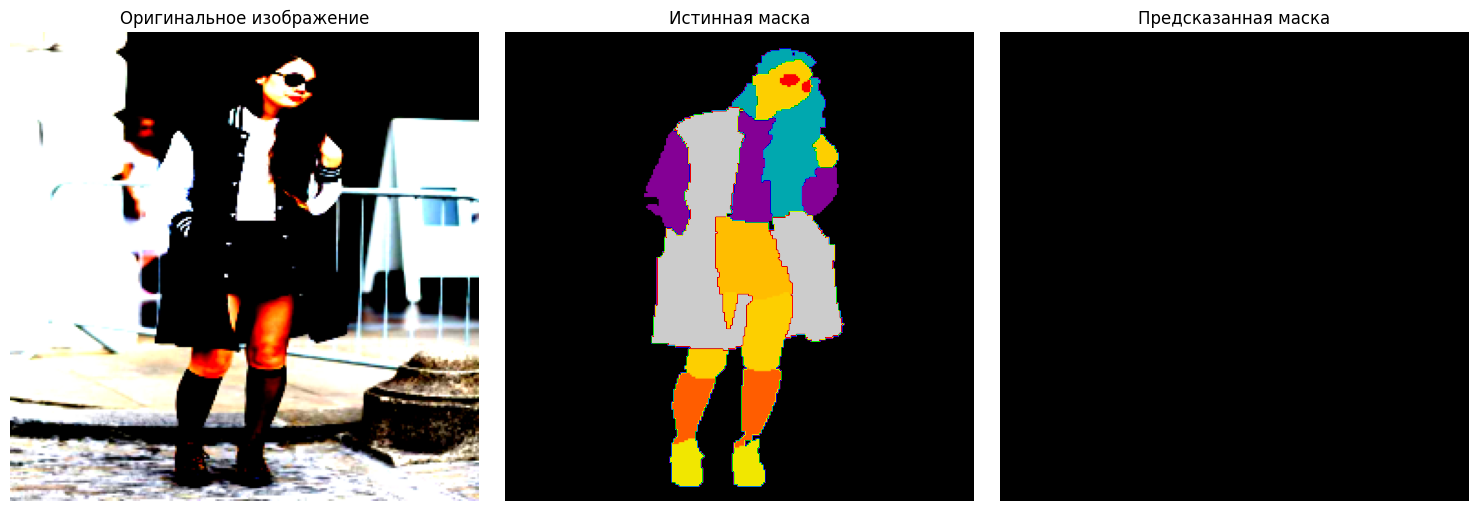

In [10]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Предполагаем, что у нас есть `image`, `mask`, и `output` из предыдущего кода.

# Преобразование выхода модели (логитов) в предсказанную маску классов
predicted_mask = torch.argmax(output, dim=1).squeeze(0)  # Форма: [256, 256]

# Визуализация оригинального изображения, истинной маски и предсказанной маски
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Оригинальное изображение (переводим в формат numpy)
axes[0].imshow(image.squeeze(0).permute(1, 2, 0).cpu().numpy())  # Меняем каналы с [C, H, W] на [H, W, C]
axes[0].set_title("Оригинальное изображение")
axes[0].axis("off")

# Истинная маска
axes[1].imshow(mask.cpu().numpy(), cmap="nipy_spectral")  # Используем цветовую карту
axes[1].set_title("Истинная маска")
axes[1].axis("off")

# Предсказанная маска
axes[2].imshow(predicted_mask.cpu().numpy(), cmap="nipy_spectral")  # Используем ту же карту
axes[2].set_title("Предсказанная маска")
axes[2].axis("off")

plt.tight_layout()
plt.show()

<p class="task" id="4"></p>

5\.  Разбейте набор данных на обучающее и валидационное множество. Обучите модель U-Net для сегментации изображения. Во время обучения выводите на экран значения функции потерь и точности прогнозов на обучающем и валидационном множестве. Обратите внимание, что выборка является несбалансированной. При расчете функции потерь примените любую известную вам технику для работы с несбалансированными выборками. 

При создании датасета допускается использовать преобразования, уменьшающие размер изображений (для ускорения процесса обучения). 

Используя обученную модель, получите предсказания для нескольких изображений и отрисуйте их.

In [11]:
from sklearn.model_selection import train_test_split

# Получаем индексы изображений
indices = list(range(len(dataset)))

# Разбиваем на обучающую и валидационную выборки (80% для обучения, 20% для валидации)
train_indices, val_indices = train_test_split(indices, test_size=0.2, random_state=42)

# Создаем подмножества для train и val
train_subset = torch.utils.data.Subset(dataset, train_indices)
val_subset = torch.utils.data.Subset(dataset, val_indices)

# Создаем DataLoader'ы
train_loader = torch.utils.data.DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_subset, batch_size=32, shuffle=False)

In [23]:
import torch.optim as optim
import torch.nn.functional as F

in_channels = 3
n_classes = 59  # Количество классов (включая фон)
model = UNet(in_channels=in_channels, n_classes=n_classes)

# Перемещение модели на GPU, если доступно
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
class_weights = torch.tensor([0.1] + [torch.rand(1).item() * (3 - 1) + 2 for _ in range(58)]).to(device)

# Определяем функцию потерь с учетом весов классов
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Оптимизатор
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Функция для расчета IoU
def iou(pred, target, n_classes):
    iou_list = []
    pred = pred.view(-1)
    target = target.view(-1)
    for i in range(n_classes):
        intersection = ((pred == i) & (target == i)).sum().item()
        union = ((pred == i) | (target == i)).sum().item()
        iou_list.append(intersection / union if union != 0 else float('nan'))
    return iou_list

# Тренировочный цикл
num_epochs = 150
for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_iou = []
    correct_train = 0
    total_train = 0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        # Обучение
        optimizer.zero_grad()
        outputs = model(images)

        # Потери
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        # IoU
        pred = torch.argmax(outputs, dim=1)
        iou_values = iou(pred, masks, n_classes)
        train_iou.append(iou_values)

        # Точность
        total_train += masks.numel()
        correct_train += (pred == masks).sum().item()

    avg_train_loss = train_loss / len(train_loader)
    avg_train_iou = [sum(iou_val) / len(iou_val) for iou_val in zip(*train_iou)]
    train_accuracy = correct_train / total_train

    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")
    if epoch % 10 == 0:
        print(f"Train IoU: {avg_train_iou}")

    # Валидация
    model.eval()
    val_loss = 0
    val_iou = []
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            # Валидация
            outputs = model(images)
            loss = criterion(outputs, masks)

            val_loss += loss.item()

            # IoU
            pred = torch.argmax(outputs, dim=1)
            iou_values = iou(pred, masks, n_classes)
            val_iou.append(iou_values)

            # Точность
            total_val += masks.numel()
            correct_val += (pred == masks).sum().item()

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou = [sum(iou_val) / len(iou_val) for iou_val in zip(*val_iou)]
    val_accuracy = correct_val / total_val

    print(f"Epoch {epoch+1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}")
    if epoch % 10 == 0:
        print(f"Val IoU: {avg_val_iou}")
    print('_'*120)

Epoch 1/150, Train Loss: 3.5307, Train Accuracy: 0.0498
Train IoU: [0.034114886597978525, 0.0, 2.275960170697013e-06, 0.0, nan, 0.0, nan, nan, nan, nan, nan, nan, nan, 0.01603874770192757, 0.00836831625024471, nan, nan, nan, nan, 2.1837202633792447e-05, nan, nan, nan, nan, nan, 0.0019650715688908616, nan, nan, nan, nan, nan, 0.00921954591713009, nan, 0.0, nan, nan, nan, nan, 0.0, 0.0, nan, 0.01984865795095104, 0.0002773617135289514, nan, nan, nan, nan, 0.0, nan, nan, nan, 0.0, nan, nan, nan, nan, nan, nan, nan]
Epoch 1/150, Val Loss: 3.1914, Val Accuracy: 0.0235
Val IoU: [4.259190635547265e-05, 0.0, 0.0, 0.0, nan, 0.0, nan, nan, nan, 0.0, nan, nan, nan, 0.02528411436804511, 0.0028051638170103277, nan, nan, nan, nan, 0.0, nan, nan, nan, nan, nan, 0.0, nan, nan, nan, nan, nan, 0.0, nan, 0.0, nan, nan, nan, nan, 0.0, 0.0, nan, 0.004177553471636663, 0.0, nan, nan, nan, nan, 0.0, nan, nan, nan, 0.0, nan, nan, nan, nan, nan, nan, nan]
_________________________________________________________

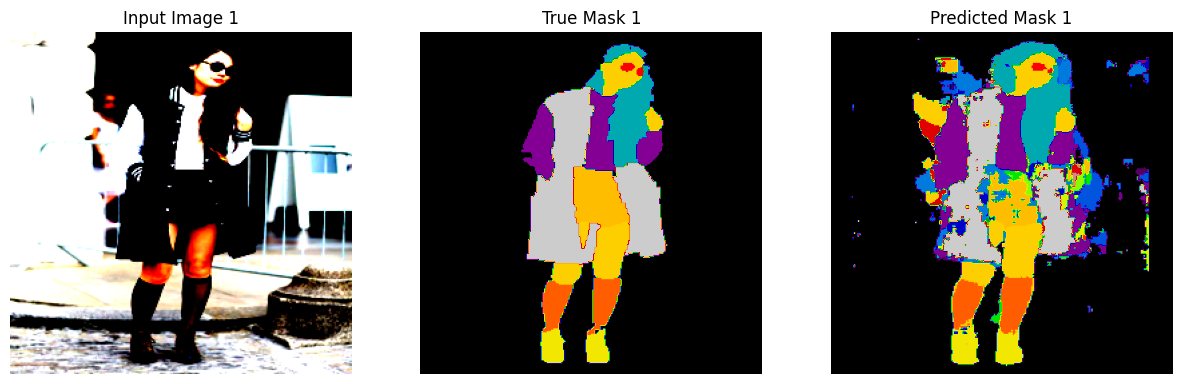

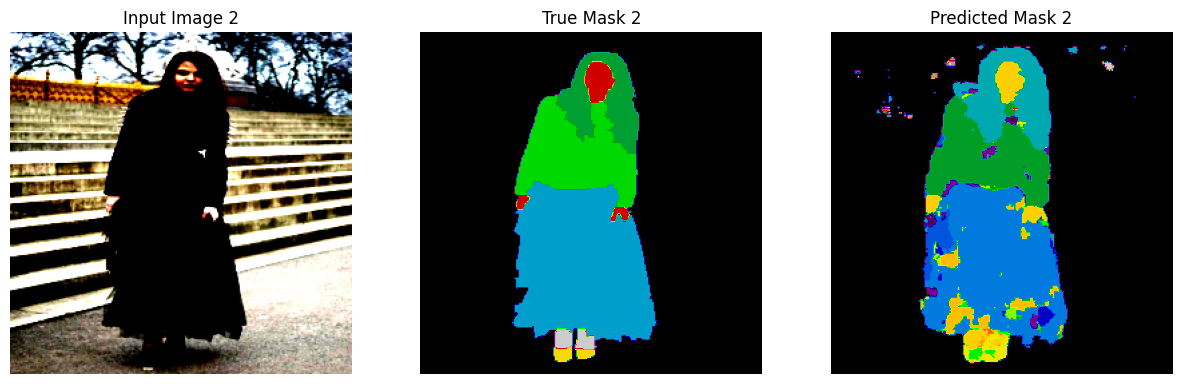

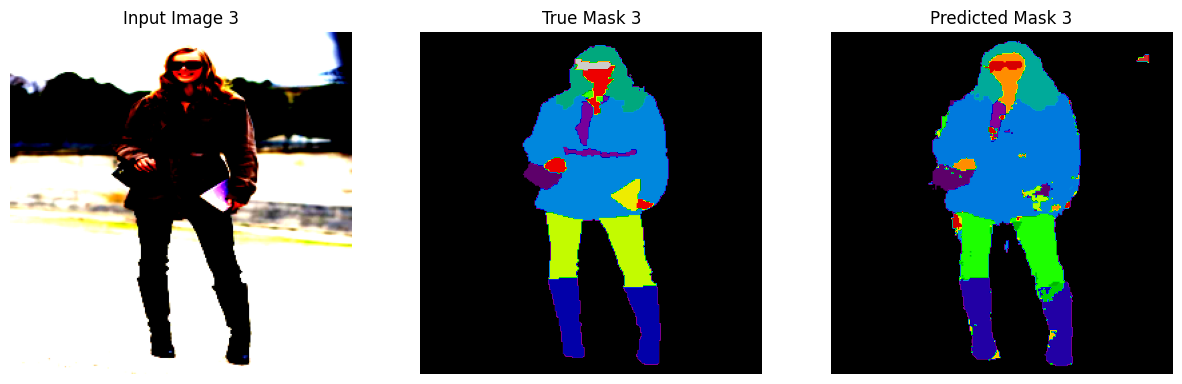

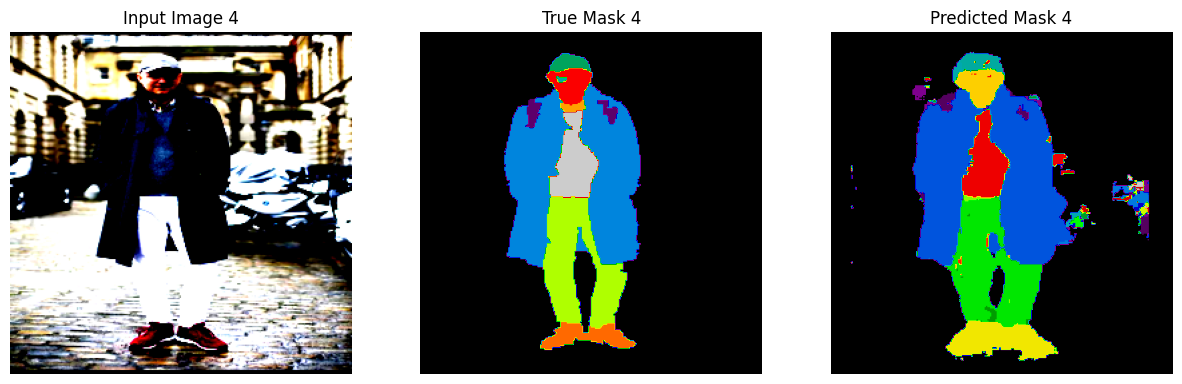

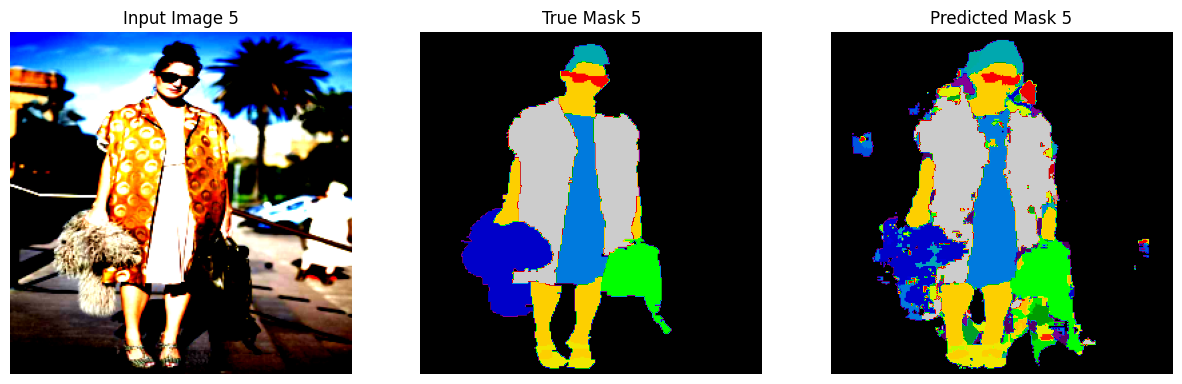

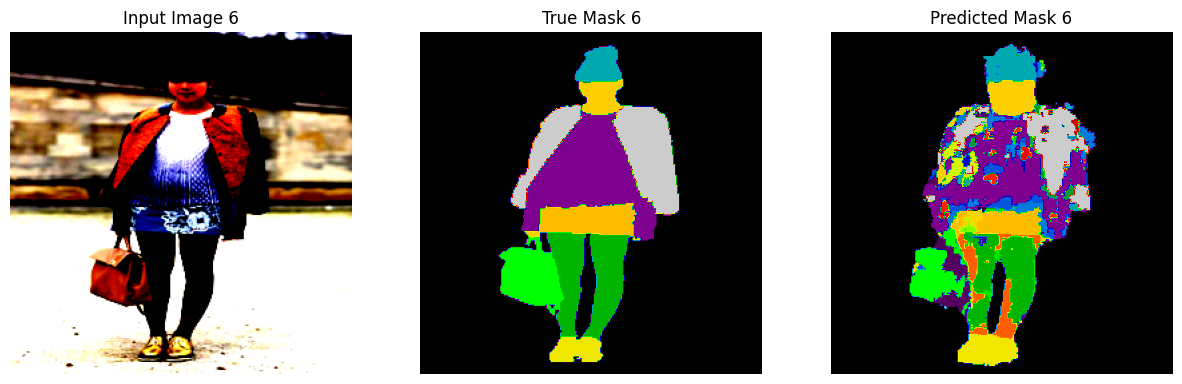

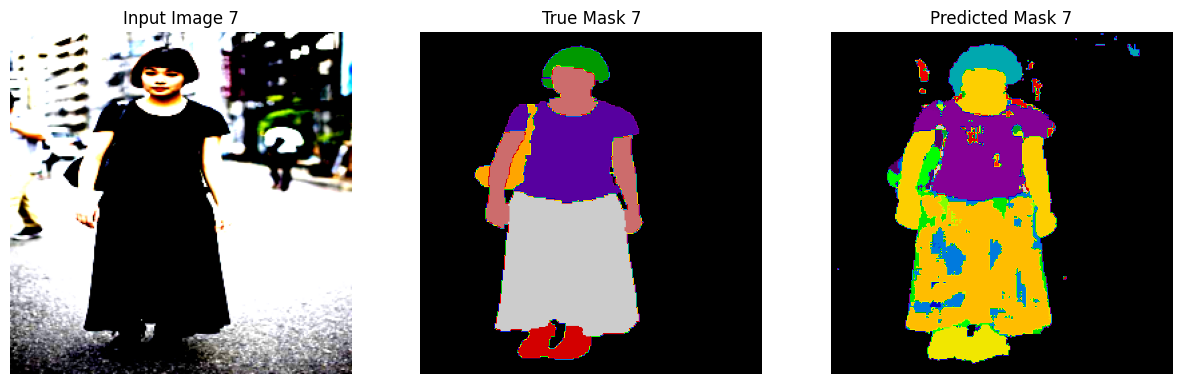

In [24]:
import matplotlib.pyplot as plt

# Подготовка изображений для предсказаний
model.eval()

# Берем 3 изображения и маски для предсказаний
image_batch = []
mask_batch = []

for i in range(7):  # Берем 3 примера
    image, mask = dataset[i]
    image_batch.append(image.unsqueeze(0))  # Добавляем batch dimension
    mask_batch.append(mask.unsqueeze(0))  # Добавляем batch dimension

# Объединяем в батч
image_batch = torch.cat(image_batch, dim=0).to(device)
mask_batch = torch.cat(mask_batch, dim=0).to(device)

# Получаем предсказания
with torch.no_grad():
    outputs = model(image_batch)

# Отрисовываем изображения и маски
for i in range(7):
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image_batch[i].permute(1, 2, 0).cpu().numpy())
    plt.title(f"Input Image {i+1}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask_batch[i].cpu().numpy(), cmap="nipy_spectral")
    plt.title(f"True Mask {i+1}")
    plt.axis("off")

    predicted_mask = torch.argmax(outputs[i], dim=0)
    plt.subplot(1, 3, 3)
    plt.imshow(predicted_mask.cpu().numpy(), cmap="nipy_spectral")
    plt.title(f"Predicted Mask {i+1}")
    plt.axis("off")

    plt.show()

<p class="task" id="5"></p>

6\.  Обучите модуль `SegformerForSemanticSegmentation` из пакета `transformers` для сегментации изображения. Во время обучения выводите на экран значения функции потерь и точности прогнозов на обучающем и валидационном множестве. Для оптимизации используйте значение функции потерь, которое возвращает вам модель.

Используя обученную модель, получите предсказания для нескольких изображений и отрисуйте их.

In [10]:
import torch
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import Compose, ToTensor, Normalize
import numpy as np
from sklearn.model_selection import train_test_split
from torch.optim import AdamW
from tqdm import tqdm
import matplotlib.pyplot as plt

In [11]:
image_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.2, 0.2, 0.2]),
])
mask_transform = transforms.Compose([
    transforms.Resize((512, 512), interpolation=InterpolationMode.NEAREST),
])

# Создаем датасет
dataset_HF = ClothesSegmentationDataset(
    image_dir=image_dir,
    mask_dir=mask_dir,
    image_transform=image_transform,
    mask_transform=mask_transform
)

In [12]:

indices = list(range(len(dataset_HF)))

# Разбиваем на обучающую и валидационную выборки (80% для обучения, 20% для валидации)
train_indices, val_indices = train_test_split(indices, test_size=0.2, random_state=42)

# Создаем подмножества для train и val
train_subset = torch.utils.data.Subset(dataset_HF, train_indices)
val_subset = torch.utils.data.Subset(dataset_HF, val_indices)

# Создаем DataLoader'ы
train_loader_HF = torch.utils.data.DataLoader(train_subset, batch_size=2, shuffle=True)
val_loader_HF = torch.utils.data.DataLoader(val_subset, batch_size=2, shuffle=False)

In [14]:
model_name = "nvidia/segformer-b0-finetuned-ade-512-512"
model = SegformerForSemanticSegmentation.from_pretrained(
    model_name,
    ignore_mismatched_sizes=True,  # Для изменения числа классов
    num_labels=59,  # Ваши классы
)
processor = SegformerImageProcessor.from_pretrained(model_name)

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([59]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([59, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [17]:
import torch.nn.functional as F

def train_epoch(model, loader, optimizer):
    model.train()
    epoch_loss = 0
    correct = 0
    total = 0

    for images, masks in tqdm(loader):
        images = images.to(device)  # [B, 3, H, W]
        masks = masks.to(device)    # [B, H, W]

        optimizer.zero_grad()
        outputs = model(pixel_values=images).logits  # [B, num_labels, H_out, W_out]

        # Приведение масок к размеру выходного тензора
        masks_resized = F.interpolate(
            masks.unsqueeze(1).float(), size=outputs.shape[2:], mode="nearest"
        ).squeeze(1).long()

        loss = criterion(outputs, masks_resized)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)  # [B, H_out, W_out]
        correct += (preds == masks_resized).sum().item()
        total += masks_resized.numel()

    accuracy = correct / total
    return epoch_loss / len(loader), accuracy


def validate_epoch(model, loader):
    model.eval()
    epoch_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, masks in tqdm(loader):
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(pixel_values=images).logits
            masks_resized = F.interpolate(
                masks.unsqueeze(1).float(), size=outputs.shape[2:], mode="nearest"
            ).squeeze(1).long()

            loss = criterion(outputs, masks_resized)
            epoch_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == masks_resized).sum().item()
            total += masks_resized.numel()

    accuracy = correct / total
    return epoch_loss / len(loader), accuracy

In [18]:
num_epochs = 10
for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader_HF, optimizer)
    val_loss, val_acc = validate_epoch(model, val_loader_HF)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.4f}")

100%|██████████| 100/100 [00:12<00:00,  8.07it/s]


Epoch 1/10
Train Loss: 2.2855, Train Accuracy: 0.6951
Val Loss: 1.2405, Val Accuracy: 0.8042


100%|██████████| 100/100 [00:08<00:00, 12.07it/s]


Epoch 2/10
Train Loss: 0.9130, Train Accuracy: 0.8333
Val Loss: 0.7000, Val Accuracy: 0.8500


100%|██████████| 100/100 [00:08<00:00, 11.67it/s]


Epoch 3/10
Train Loss: 0.6367, Train Accuracy: 0.8603
Val Loss: 0.5798, Val Accuracy: 0.8617


... (10 outputs left out)

100%|██████████| 100/100 [00:08<00:00, 12.34it/s]


Epoch 9/10
Train Loss: 0.3415, Train Accuracy: 0.9102
Val Loss: 0.4196, Val Accuracy: 0.8878


100%|██████████| 100/100 [00:08<00:00, 12.28it/s]

Epoch 10/10
Train Loss: 0.3082, Train Accuracy: 0.9184
Val Loss: 0.4207, Val Accuracy: 0.8888


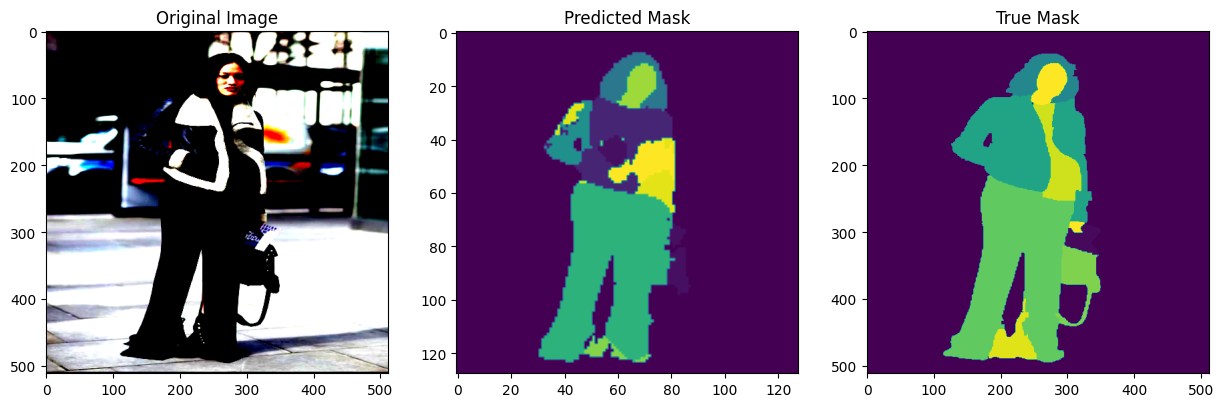

In [21]:
def predict(model, dataset, idx):
    model.eval()
    image, mask = dataset[idx]
    image = image.unsqueeze(0).to(device)  # Добавляем размер пакета
    with torch.no_grad():
        outputs = model(pixel_values=image).logits
        preds = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()
    return image.squeeze(0).cpu().numpy(), preds, mask.numpy()

# Визуализация
image, pred, mask = predict(model, val_subset, idx=0)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image.transpose(1, 2, 0))  # Приведение к HWC
plt.subplot(1, 3, 2)
plt.title("Predicted Mask")
plt.imshow(pred)
plt.subplot(1, 3, 3)
plt.title("True Mask")
plt.imshow(mask)
plt.show()